# Chapter 66: Tax Incidence, Elasticity, Salience, and Revenue

This notebook reruns four worked examples from the chapter: a tax buyers only partly notice, the split of a tax between buyers and sellers in the short and long run, a revenue curve with and without a peak, and a tax farm against a salaried collector. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(i) for i in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def salient_price(p, t, theta, a=90.0, b=2.0):
    """Buyers react to the decision price p + theta t; demand q = a - b p_tilde; cash price p + t; revenue t q.

    Principle: tax-salience. Book (ch066): p = 30, t = 6, q = 90 - 2 p_tilde: theta 0.25 gives 31.5, 27, 162;
    theta 0.75 gives 34.5, 21, 126; theta 1 gives 36 and 18. Pretax price held fixed.
    """
    p_tilde = p + theta * t
    q = max(0.0, a - b * p_tilde)
    return {"p_tilde": p_tilde, "q": q, "cash_price": p + t, "revenue": t * q}


def tax_incidence_linear(a_d, b_d, a_s, b_s, t):
    """Per-unit tax t remitted by sellers with demand Q = a_d - b_d p_b and supply Q = a_s + b_s p_s.

    Principle: tax-incidence-and-elasticity. Book (ch066): 180 - 3 p_b and 30 + p_s, t = 8: p0 = 37.5,
    Q0 = 67.5, p_s = 31.5, p_b = 39.5, Q = 61.5, buyer share 1/4, revenue 492; long-run supply -45 + 3 p_s:
    p_s = 33.5, p_b = 41.5, Q = 55.5, revenue 444.
    """
    p0 = (a_d - a_s) / (b_d + b_s)
    q0 = a_s + b_s * p0
    p_s = (a_d - b_d * t - a_s) / (b_d + b_s)
    p_b = p_s + t
    q = a_s + b_s * p_s
    eps_d = b_d * p0 / q0
    eps_s = b_s * p0 / q0
    return {"p0": p0, "Q0": q0, "p_s": p_s, "p_b": p_b, "Q": q, "revenue": t * q,
            "buyer_burden": p_b - p0, "seller_burden": p0 - p_s, "buyer_share": (p_b - p0) / t,
            "eps_d": eps_d, "eps_s": eps_s, "share_from_elasticities": eps_s / (eps_s + eps_d)}


def laffer_revenue(t, base0, k):
    """Revenue R(t) = t B(t) with a linear base B(t) = base0 (1 - k t).

    Principle: laffer-curve-and-tax-base. Book (ch066): base0 = 1,200, k = 0.8 gives B(0.80) = 432,
    R(0.80) = 345.6 and R(0.625) = 375; k = 0.4 gives R(1) = 720. Peak at t = 1/(2k).
    Returns dict with base, revenue and the revenue-maximizing rate t_peak.
    """
    base = base0 * (1 - k * t)
    return {"base": base, "revenue": t * base, "t_peak": 1 / (2 * k)}


def base_elasticity(t, base0, k):
    """Elasticity of the linear base B = base0 (1 - k t) with respect to the rate: t (base0 k) / B.

    Principle: laffer-curve-and-tax-base. Book (ch066): 0.80(960)/432 = 16/9 > 1 at k = 0.8.
    Revenue falls when the rate rises exactly when this exceeds 1.
    """
    return t * base0 * k / (base0 * (1 - k * t))


def tax_farm_regimes(F, m, w=15.0, y_low=120.0, y_bad=130.0, y_good=170.0, cost_high=12.0):
    """State net receipts under an unmonitored salary, a fixed tax farm, and monitored administration.

    Principle: tax-farming-principal-agent. Book (ch066): E[Y_H] = 150; salary nets 120 - 15 = 105;
    farm F = 110 with farmer expected profit 150 - 110 - 12 = 28 (outcomes 8 and 48); monitored
    150 - 15 - 30 = 105, then 150 - 15 - 12 = 123.
    """
    ey = 0.5 * y_bad + 0.5 * y_good
    farmer_high = ey - F - cost_high
    farmer_low = y_low - F
    high = farmer_high > farmer_low
    return {"EY_high": ey, "salary": y_low - w, "farm_profit_high": farmer_high, "farm_profit_low": farmer_low,
            "farm_high_effort": high, "farm": F if high else min(F, y_low),
            "farm_outcomes": (y_bad - F - cost_high, y_good - F - cost_high),
            "monitored": ey - w - m, "tie_monitoring_cost": ey - w - F}


plt.rcParams.update(HOUSE_RC)


behavioral = SimpleNamespace(salient_price=salient_price)


equilibrium = SimpleNamespace(tax_incidence_linear=tax_incidence_linear)


public = SimpleNamespace(laffer_revenue=laffer_revenue, base_elasticity=base_elasticity, tax_farm_regimes=tax_farm_regimes)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'tax-salience': {'p': 30,
                  't': 6,
                  'a': 90,
                  'b': 2,
                  'theta0': 0.25,
                  'theta1': 0.75,
                  'p_tilde0': 31.5,
                  'q0': 27,
                  'cash_price': 36,
                  'R0': 162,
                  'p_tilde1': 34.5,
                  'q1': 21,
                  'R1': 126,
                  'q_fall': 6,
                  'R_fall': 36,
                  'q_full': 18},
 'tax-incidence-and-elasticity': {'a_d': 180,
                                  'b_d': 3,
                                  'a_s': 30,
                                  'b_s': 1,
                                  't': 8,
                                  'p0': 37.5,
                                  'Q0': 67.5,
                                  'p_s': 31.5,
                                  'p_b': 39.5,
                                  'Q1': 61.5,
                                  'buyer_share': 0.25,
                                  'R1': 492,
                                  'eps_d': 1.6666666666666667,
                                  'eps_s': 0.5555555555555556,
                                  'long_run': {'a_s': -45,
                                               'b_s': 3,
                                               'p_s': 33.5,
                                               'p_b': 41.5,
                                               'Q2': 55.5,
                                               'R2': 444}},
 'laffer-curve-and-tax-base': {'base0': 1200,
                               'k_low': 0.4,
                               'k_high': 0.8,
                               'R_low_at_1': 720,
                               't_peak': 0.625,
                               'B_peak': 600,
                               'R_peak': 375,
                               'B_080': 432,
                               'R_080': 345.6,
                               'gain': 29.4,
                               'eps_080': 1.7777777777777777},
 'tax-farming-principal-agent': {'y_low': 120,
                                 'y_bad': 130,
                                 'y_good': 170,
                                 'cost_high': 12,
                                 'w': 15,
                                 'F': 110,
                                 'EY_high': 150,
                                 'salary_net': 105,
                                 'farm_low_profit': 10,
                                 'farm_high_profit': 28,
                                 'outcomes': (8, 48),
                                 'm0': 30,
                                 'monitored0': 105,
                                 'm1': 12,
                                 'monitored1': 123},
 'constructed': {'tax-salience': {'theta': [0.5], 't': [4, 8]},
                 'tax-incidence-and-elasticity': {'t': [4, 12]},
                 'laffer-curve-and-tax-base': {'k': [0.6], 't': [0.5]},
                 'tax-farming-principal-agent': {'m': [20], 'F': [100, 120]}}}


def short(x, digits=3):
    """Up to `digits` decimals, trailing zeros removed: 0.25, 0.5, 1."""
    return f"{x:.{digits}f}".rstrip("0").rstrip(".")


def salience_picture(theta=0.25, t=6):
    bv = BV["tax-salience"]
    p, a, b = bv["p"], bv["a"], bv["b"]
    r = behavioral.salient_price(p, t, theta, a, b)
    full = behavioral.salient_price(p, t, 1.0, a, b)
    fig, ax = new_figure()
    qs = np.linspace(0, 50, 100)
    ax.plot(qs, (a - qs) / b, color=PALETTE["navy"], linewidth=2.2)
    label(ax, 46, (a - 46) / b, "demand q = 90 - 2p", col="navy", dx=-6, dy=-8, ha="right", va="top")
    ax.fill_between([0, r["q"]], p, p + t, color=PALETTE["gold"], alpha=0.22, linewidth=0)
    ax.text(0.02, 0.04, f"shaded area: revenue {num(t, 0)} x {num(r['q'], 0)} = {num(r['revenue'], 0)}",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=10.5, color=PALETTE["gold"])
    hline(ax, p, f"pretax price {num(p, 0)}", col="grey", x_frac=0.02, va="top")
    if theta == 1:
        hline(ax, r["p_tilde"], f"decision = cash price {num(r['p_tilde'], 0)}", col="terracotta",
              x_frac=0.6, va="bottom")
    else:
        hline(ax, r["cash_price"], f"cash price {num(r['cash_price'], 0)}", col="ink", x_frac=0.66, va="bottom")
        hline(ax, r["p_tilde"], f"decision price {num(r['p_tilde'], 1)}", col="terracotta", x_frac=0.66, va="top")
    mark(ax, r["q"], r["p_tilde"], f"q = {num(r['q'], 0)}", col="terracotta", dx=8, dy=6)
    ax.set_xlim(0, 50)
    ax.set_ylim(20, 46)
    ax.set_xlabel("Quantity bought q")
    ax.set_ylabel("Price per unit")
    metrics = {"Decision price": num(r["p_tilde"], 1), "Quantity": num(r["q"], 0),
               "Cash price paid": num(r["cash_price"], 0), "Tax revenue": num(r["revenue"], 0),
               "Revenue at full attention": num(full["revenue"], 0)}
    steps = [f"Decision price = 30 + {short(theta)}({num(t, 0)}) = {num(r['p_tilde'], 1)}",
             f"q = 90 - 2({num(r['p_tilde'], 1)}) = {num(r['q'], 0)}",
             f"Cash price = 30 + {num(t, 0)} = {num(r['cash_price'], 0)}",
             f"Revenue = {num(t, 0)}({num(r['q'], 0)}) = {num(r['revenue'], 0)}"]
    if theta == 1:
        gap = "Buyers notice the whole tax, so they react to the price they actually pay."
    else:
        extra = r["q"] - full["q"]
        gap = (f"Buyers notice only {short(100 * theta, 1)} percent of the tax, so they buy {num(extra, 0)} more "
               f"units than at full attention ({num(full['q'], 0)}) and revenue is {num(r['revenue'], 0)} instead "
               f"of {num(full['revenue'], 0)}.")
        steps.append(f"Full attention: q = 90 - 2({num(full['p_tilde'], 0)}) = {num(full['q'], 0)}, "
                     f"revenue {num(t, 0)}({num(full['q'], 0)}) = {num(full['revenue'], 0)}")
    interp = (f"The decision price is 30 + {short(theta)} x {num(t, 0)} = {num(r['p_tilde'], 1)}, so q = 90 - "
              f"2 x {num(r['p_tilde'], 1)} = {num(r['q'], 0)}. Every unit still costs {num(r['cash_price'], 0)} in "
              f"cash and raises {num(t, 0)} of tax, so revenue is {num(r['revenue'], 0)}. {gap}")
    alt = (f"Demand line q = 90 - 2p with the pretax price 30, the decision price {num(r['p_tilde'], 1)} and the cash "
           f"price {num(r['cash_price'], 0)} drawn as horizontal lines. Buyers choose {num(r['q'], 0)} units; the "
           f"shaded revenue rectangle is {num(t, 0)} high and {num(r['q'], 0)} wide, {num(r['revenue'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


SUPPLY = {"short": (30, 1), "long": (-45, 3)}


def incidence_picture(horizon="short", t=8):
    bv = BV["tax-incidence-and-elasticity"]
    a_d, b_d = bv["a_d"], bv["b_d"]
    a_s, b_s = SUPPLY[horizon]
    r = equilibrium.tax_incidence_linear(a_d, b_d, a_s, b_s, t)
    fig, (ax, bx) = new_figure(ncols=2)
    qs = np.linspace(35, 80, 100)
    ax.plot(qs, (a_d - qs) / b_d, color=PALETTE["navy"], linewidth=2.2)
    ax.plot(qs, (qs - a_s) / b_s, color=PALETTE["teal"], linewidth=2.2)
    label(ax, 79, (a_d - 79) / b_d, "demand", col="navy", dx=-4, dy=-8, ha="right", va="top")
    sup_name = "short-run supply" if horizon == "short" else "long-run supply"
    label(ax, 77, (77 - a_s) / b_s, sup_name, col="teal", dx=-8, dy=4, ha="right")
    ax.plot([r["Q"], r["Q"]], [r["p_s"], r["p_b"]], color=PALETTE["terracotta"], linewidth=4, solid_capstyle="butt")
    mark(ax, r["Q0"], r["p0"], col="ink")
    ax.text(0.98, 0.04, f"black dot: no tax, Q = {num(r['Q0'], 1)}, p = {num(r['p0'], 1)}", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=10.5, color=PALETTE["ink"])
    mark(ax, r["Q"], r["p_b"], f"buyers pay {num(r['p_b'], 1)}", col="navy", dx=-8, dy=4, ha="right")
    mark(ax, r["Q"], r["p_s"], f"sellers keep {num(r['p_s'], 1)}", col="teal", dx=-8, dy=-4, ha="right", va="top")
    ax.set_xlim(35, 80)
    ax.set_ylim(20, 50)
    ax.set_xlabel("Quantity Q")
    ax.set_ylabel("Price")
    bar_compare(bx, ["buyers", "sellers"], [r["buyer_burden"], r["seller_burden"]], colors=["navy", "teal"],
                value_labels=[f"{num(r['buyer_burden'], 1)} of {num(t, 0)}", f"{num(r['seller_burden'], 1)} of {num(t, 0)}"],
                ylabel="Price change per unit", xlabel="Who bears the tax")
    bx.set_ylim(0, 10)
    share = r["buyer_share"]
    frac = {0.25: "1/4", 0.5: "1/2"}.get(round(share, 6), num(share, 2))
    metrics = {"Seller price p_s": num(r["p_s"], 1), "Buyer price p_b": num(r["p_b"], 1),
               "Quantity": num(r["Q"], 1), "Buyer share": f"{frac} ({num(100 * share, 0)}%)",
               "Tax revenue": num(r["revenue"], 1)}
    supply_txt = "30 + p_s" if horizon == "short" else "-45 + 3p_s"
    denom = b_d + b_s
    num_s = a_d - b_d * t - a_s
    steps = [f"180 - 3(p_s + {num(t, 0)}) = {supply_txt}",
             f"{num(denom, 0)}p_s = {num(a_d - b_d * t, 0)} - ({num(a_s, 0)}) = {num(num_s, 0)}, so p_s = {num(r['p_s'], 1)}",
             f"p_b = {num(r['p_s'], 1)} + {num(t, 0)} = {num(r['p_b'], 1)}; Q = {num(r['Q'], 1)}",
             f"Buyer share = ({num(r['p_b'], 1)} - 37.5) / {num(t, 0)} = {num(r['buyer_burden'], 1)} / {num(t, 0)} = {frac}",
             f"Revenue = {num(t, 0)}({num(r['Q'], 1)}) = {num(r['revenue'], 1)}"]
    if horizon == "short":
        why = ("Supply elasticity at the pretax point is 5/9 against demand's 5/3, so sellers, the less responsive "
               "side, bear three quarters.")
    else:
        why = ("Long-run supply elasticity at the pretax point is 5/3, equal to demand's, so the two sides bear "
               "equal shares.")
    interp = (f"With supply {supply_txt}, the buyer price rises from 37.5 to {num(r['p_b'], 1)} and the seller price "
              f"falls to {num(r['p_s'], 1)}: buyers bear {num(r['buyer_burden'], 1)} and sellers "
              f"{num(r['seller_burden'], 1)} of the {num(t, 0)} tax. {why} Revenue is {num(t, 0)} x "
              f"{num(r['Q'], 1)} = {num(r['revenue'], 1)}.")
    alt = (f"Left: demand and {sup_name} crossing at (67.5, 37.5), with the {num(t, 0)} tax wedge at quantity "
           f"{num(r['Q'], 1)} between seller price {num(r['p_s'], 1)} and buyer price {num(r['p_b'], 1)}. Right: "
           f"buyers bear {num(r['buyer_burden'], 1)} and sellers {num(r['seller_burden'], 1)} per unit.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def laffer_picture(k=0.8, t=0.8):
    base0 = BV["laffer-curve-and-tax-base"]["base0"]
    r = public.laffer_revenue(t, base0, k)
    eps = public.base_elasticity(t, base0, k)
    ts = np.linspace(0, 1, 200)
    rs = [public.laffer_revenue(x, base0, k)["revenue"] for x in ts]
    top = max(rs)
    fig, ax = new_figure()
    ax.plot(ts, rs, color=PALETTE["teal"], linewidth=2.2)
    peak_in = r["t_peak"] <= 1
    if peak_in:
        vline(ax, r["t_peak"], f"peak at t = {short(r['t_peak'], 4)}", col="grey",
              ha="right" if r["t_peak"] > 0.7 else "left", y_frac=0.97)
    text = f"R({short(t)}) = {num(r['revenue'], 1)}"
    if abs(t - r["t_peak"]) < 1e-9:
        mark(ax, t, r["revenue"], text, col="terracotta", dx=0, dy=10, ha="center")
    elif t < r["t_peak"]:
        mark(ax, t, r["revenue"], text, col="terracotta", dx=-6, dy=10, ha="right")
    else:
        mark(ax, t, r["revenue"], text, col="terracotta", dx=-8, dy=-10, ha="right", va="top")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, top * 1.3)
    ax.set_xlabel("Tax rate t")
    ax.set_ylabel(f"Revenue R(t) = 1200 t (1 - {short(k)}t)")
    is_peak = abs(eps - 1) < 1e-9
    if is_peak:
        verdict = ("The base elasticity is exactly 1: this is the peak, so a small rate change leaves revenue "
                   "unchanged to first order.")
        status = "at the peak (elasticity = 1)"
    elif eps > 1:
        verdict = (f"The base elasticity {num(eps, 3)} is above 1, so this rate is on the inverse side: a lower rate "
                   f"raises revenue.")
        status = "lower rate raises revenue"
    else:
        verdict = (f"The base elasticity {num(eps, 3)} is below 1, so a slightly higher rate still raises revenue.")
        status = "higher rate raises revenue"
    peak_txt = (f"The revenue peak is at t = 1/(2 x {short(k)}) = {short(r['t_peak'], 4)}, where revenue is "
                f"{num(public.laffer_revenue(r['t_peak'], base0, k)['revenue'], 1)}." if peak_in else
                f"The peak would be at t = 1/(2 x {short(k)}) = {short(r['t_peak'], 4)}, outside rates from 0 to 1, "
                f"so revenue rises all the way to t = 1.")
    metrics = {"Base B(t)": num(r["base"], 1), "Revenue R(t)": num(r["revenue"], 1),
               "Base elasticity": num(eps, 3), "Revenue-maximizing rate": short(r["t_peak"], 4)
               + ("" if peak_in else " (above 1)"), "Reading": status}
    steps = [f"B = 1200(1 - {short(k)} x {short(t)}) = 1200({short(1 - k * t, 4)}) = {num(r['base'], 1)}",
             f"R = {short(t)} x {num(r['base'], 1)} = {num(r['revenue'], 1)}",
             f"Elasticity = {short(t)}({num(base0 * k, 0)}) / {num(r['base'], 1)} = {num(t * base0 * k, 1)} / "
             f"{num(r['base'], 1)} = {num(eps, 3)}",
             f"Peak rate = 1 / (2 x {short(k)}) = {short(r['t_peak'], 4)}"]
    interp = (f"At t = {short(t)} the base is {num(r['base'], 1)} and revenue {num(r['revenue'], 1)}. {verdict} "
              f"{peak_txt}")
    alt = (f"Revenue curve R(t) = 1200 t (1 - {short(k)} t) for rates 0 to 1, with the chosen rate {short(t)} marked "
           f"at revenue {num(r['revenue'], 1)}" + (f" and the peak at {short(r['t_peak'], 4)}." if peak_in else
                                                   "; the curve is still rising at t = 1."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def farm_picture(m=30, f=110):
    r = public.tax_farm_regimes(f, m)
    names = ["Salary,\nunmonitored", "Tax farm", "Salary,\nmonitored"]
    vals = [r["salary"], r["farm"], r["monitored"]]
    best = max(vals)
    plain = ["unmonitored salary", "tax farm", "monitored salary"]
    winners = [n for n, v in zip(plain, vals) if abs(v - best) < 1e-9]
    fig, ax = new_figure()
    cols = ["terracotta" if abs(v - best) < 1e-9 else "light" for v in vals]
    bar_compare(ax, names, vals, colors=cols, value_labels=[num(v, 0) for v in vals],
                ylabel="Expected net receipts to the state", xlabel="Collection arrangement")
    ax.set_ylim(0, 150)
    lo, hi = r["farm_outcomes"]
    ax.text(0.98, 0.97, f"farmer profit: {num(lo, 0)} or {num(hi, 0)}, expected {num(r['farm_profit_high'], 0)}",
            transform=ax.transAxes, ha="right", va="top", fontsize=10.5, color=PALETTE["ink"])
    if len(winners) == 1:
        verdict = f"The {winners[0]} arrangement nets the state the most, {num(best, 0)}."
        best_txt = winners[0].capitalize()
    else:
        verdict = f"Tie: the {join_and(winners)} arrangements both net {num(best, 0)}."
        best_txt = "Tie: " + join_and(winners)
    metrics = {"Unmonitored salary": num(r["salary"], 0), "Tax farm": num(r["farm"], 0),
               "Monitored salary": num(r["monitored"], 0), "Farmer expected profit": num(r["farm_profit_high"], 0),
               "Farmer outcomes": f"{num(lo, 0)} or {num(hi, 0)}", "Best for the state": best_txt}
    steps = ["E[Y_H] = 0.5(130) + 0.5(170) = 150",
             "Unmonitored salary: low effort, 120 - 15 = 105",
             f"Farm: high effort {num(r['farm_profit_high'], 0)} = 150 - {num(f, 0)} - 12 beats low effort "
             f"120 - {num(f, 0)} = {num(r['farm_profit_low'], 0)}, so the state gets {num(f, 0)}",
             f"Monitored salary: 150 - 15 - {num(m, 0)} = {num(r['monitored'], 0)}",
             f"Monitoring cost that ties the farm: 150 - 15 - {num(f, 0)} = {num(r['tie_monitoring_cost'], 0)}"]
    interp = (f"A salaried collector without monitoring shirks and nets 105. The farmer paying {num(f, 0)} chooses "
              f"high effort, expecting 150 - {num(f, 0)} - 12 = {num(r['farm_profit_high'], 0)} with outcomes "
              f"{num(lo, 0)} or {num(hi, 0)}. Monitoring at cost {num(m, 0)} nets 150 - 15 - {num(m, 0)} = "
              f"{num(r['monitored'], 0)}. {verdict} Monitoring would tie the farm at a cost of "
              f"{num(r['tie_monitoring_cost'], 0)}.")
    alt = (f"Bars of expected net receipts: unmonitored salary 105, tax farm {num(f, 0)}, monitored salary "
           f"{num(r['monitored'], 0)} at monitoring cost {num(m, 0)}. {verdict}")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Tax salience: attention changes the tax buyers react to

The pretax price is 30, the tax 6 per unit and buyers react to the decision price $\widetilde p=30+\theta t$:

$$q=90-2\widetilde p$$

With $\theta_0=0.25$ the decision price is 31.5, quantity 27, and revenue $R_0=6(27)=162$.

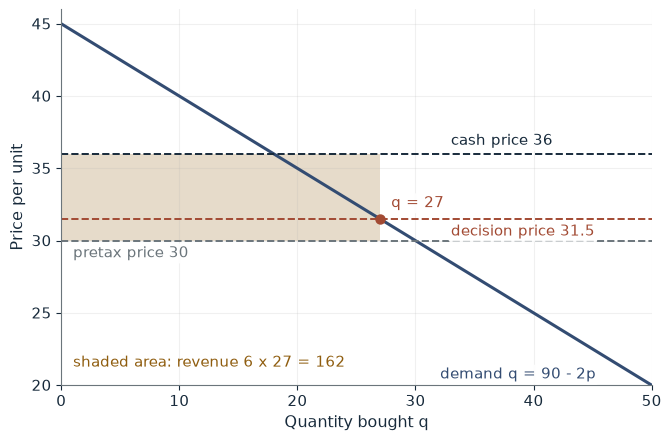

Decision price             31.5
Quantity                   27
Cash price paid            36
Tax revenue                162
Revenue at full attention  108

Worked steps:
  1. Decision price = 30 + 0.25(6) = 31.5
  2. q = 90 - 2(31.5) = 27
  3. Cash price = 30 + 6 = 36
  4. Revenue = 6(27) = 162
  5. Full attention: q = 90 - 2(36) = 18, revenue 6(18) = 108

The decision price is 30 + 0.25 x 6 = 31.5, so q = 90 - 2 x 31.5 = 27. Every unit still costs 36 in cash and raises 6 of tax, so revenue is 162. Buyers notice only 25 percent of the tax, so they buy 9 more units than at full attention (18) and revenue is 162 instead of 108.


In [2]:
show(salience_picture(theta=0.25, t=6))

Change one input, `theta`, and hold the others at the book's values:

In [3]:
sweep(salience_picture, 'theta', [0.25, 0.5, 0.75, 1.0], {'t': 6}, ['Decision price', 'Quantity', 'Tax revenue'])

theta | Decision price | Quantity | Tax revenue
0.25 | 31.5 | 27 | 162
0.5 | 33.0 | 24 | 144
0.75 | 34.5 | 21 | 126
1.0 | 36.0 | 18 | 108


Buyers still pay 36 in cash, but react to 31.5. An inclusive label ($\theta=0.75$) cuts quantity to 21 and revenue to 126, a fall of 36; full attention gives 18 units and 108.

## 2. Tax incidence and elasticity: who pays depends on how fast supply responds

Sellers remit a tax of 8 and $p_b=p_s+8$.

$$Q_D=180-3p_b,\qquad Q_S=30+p_s$$

$$180-3(p_s+8)=30+p_s$$

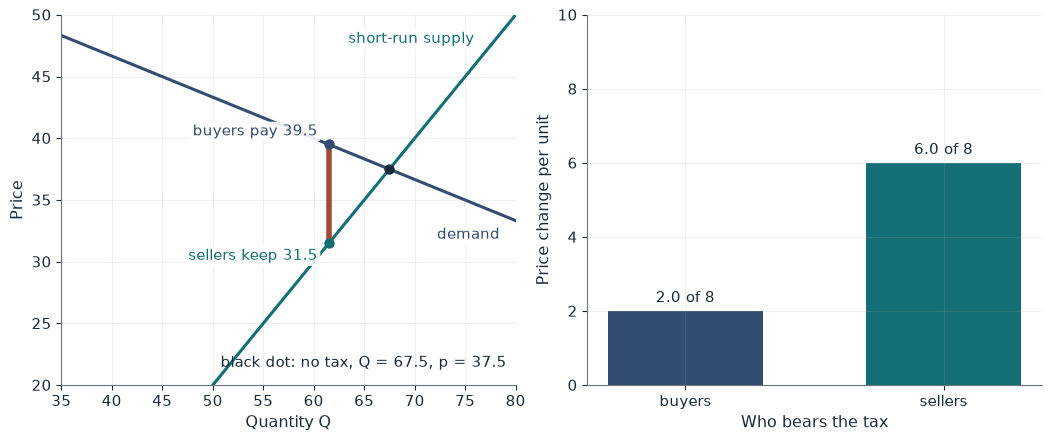

Seller price p_s  31.5
Buyer price p_b   39.5
Quantity          61.5
Buyer share       1/4 (25%)
Tax revenue       492.0

Worked steps:
  1. 180 - 3(p_s + 8) = 30 + p_s
  2. 4p_s = 156 - (30) = 126, so p_s = 31.5
  3. p_b = 31.5 + 8 = 39.5; Q = 61.5
  4. Buyer share = (39.5 - 37.5) / 8 = 2.0 / 8 = 1/4
  5. Revenue = 8(61.5) = 492.0

With supply 30 + p_s, the buyer price rises from 37.5 to 39.5 and the seller price falls to 31.5: buyers bear 2.0 and sellers 6.0 of the 8 tax. Supply elasticity at the pretax point is 5/9 against demand's 5/3, so sellers, the less responsive side, bear three quarters. Revenue is 8 x 61.5 = 492.0.


In [4]:
show(incidence_picture(horizon='short', t=8))

Change one input, `horizon`, and hold the others at the book's values:

In [5]:
sweep(incidence_picture, 'horizon', ['short', 'long'], {'t': 8}, ['Seller price p_s', 'Buyer price p_b', 'Buyer share', 'Tax revenue'])

horizon | Seller price p_s | Buyer price p_b | Buyer share | Tax revenue
short | 31.5 | 39.5 | 1/4 (25%) | 492.0
long | 33.5 | 41.5 | 1/2 (50%) | 444.0


In the short run buyers bear 2 of the 8 (one quarter) and revenue is 492. With long-run supply $-45+3p_s$ through the same pretax point, each side bears 4 and revenue is 444.

## 3. The Laffer curve and the tax base: a peak appears only when the base is sensitive

$$B_H(t)=1200(1-0.8t)$$

Revenue is $tB(t)$ and the base elasticity at 0.80 is

$$\varepsilon_B(0.80)=\frac{0.80(960)}{432}=\frac{16}{9}>1$$

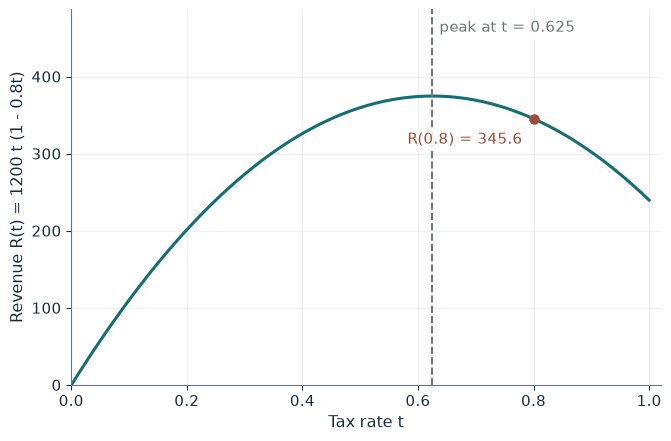

Base B(t)                432.0
Revenue R(t)             345.6
Base elasticity          1.778
Revenue-maximizing rate  0.625
Reading                  lower rate raises revenue

Worked steps:
  1. B = 1200(1 - 0.8 x 0.8) = 1200(0.36) = 432.0
  2. R = 0.8 x 432.0 = 345.6
  3. Elasticity = 0.8(960) / 432.0 = 768.0 / 432.0 = 1.778
  4. Peak rate = 1 / (2 x 0.8) = 0.625

At t = 0.8 the base is 432.0 and revenue 345.6. The base elasticity 1.778 is above 1, so this rate is on the inverse side: a lower rate raises revenue. The revenue peak is at t = 1/(2 x 0.8) = 0.625, where revenue is 375.0.


In [6]:
show(laffer_picture(k=0.8, t=0.8))

Change one input, `t`, and hold the others at the book's values:

In [7]:
sweep(laffer_picture, 't', [0.5, 0.625, 0.8, 1.0], {'k': 0.8}, ['Base B(t)', 'Revenue R(t)', 'Base elasticity'])

t | Base B(t) | Revenue R(t) | Base elasticity
0.5 | 720.0 | 360.0 | 0.667
0.625 | 600.0 | 375.0 | 1.000
0.8 | 432.0 | 345.6 | 1.778
1.0 | 240.0 | 240.0 | 4.000


At $t=0.80$ revenue is 345.6; cutting to the peak rate 0.625 raises it to 375. With the less sensitive base $B_L(t)=1200(1-0.4t)$ (`k=0.4`) revenue rises all the way to 720 at $t=1$.

## 4. Tax farming and the principal-agent problem: farm or salaried collector

High effort costs the collector 12 and collects 130 or 170 with equal probability:

$$\mathbb{E}[Y_H]=0.5(130)+0.5(170)=150$$

A farmer paying 110 expects $150-110-12=28$; monitored administration nets $150-15-30=105$, then $150-15-12=123$ once monitoring costs 12.

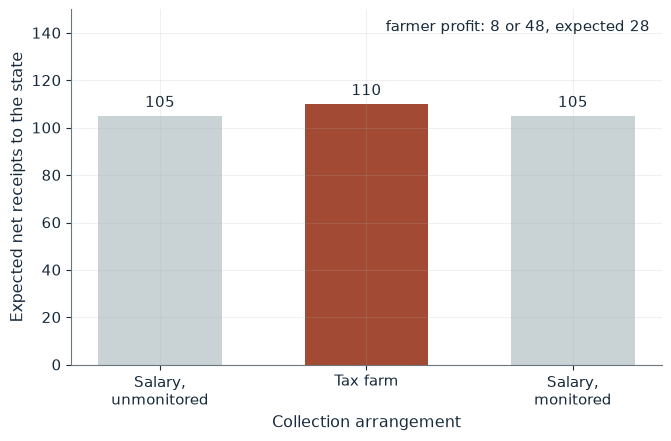

Unmonitored salary      105
Tax farm                110
Monitored salary        105
Farmer expected profit  28
Farmer outcomes         8 or 48
Best for the state      Tax farm

Worked steps:
  1. E[Y_H] = 0.5(130) + 0.5(170) = 150
  2. Unmonitored salary: low effort, 120 - 15 = 105
  3. Farm: high effort 28 = 150 - 110 - 12 beats low effort 120 - 110 = 10, so the state gets 110
  4. Monitored salary: 150 - 15 - 30 = 105
  5. Monitoring cost that ties the farm: 150 - 15 - 110 = 25

A salaried collector without monitoring shirks and nets 105. The farmer paying 110 chooses high effort, expecting 150 - 110 - 12 = 28 with outcomes 8 or 48. Monitoring at cost 30 nets 150 - 15 - 30 = 105. The tax farm arrangement nets the state the most, 110. Monitoring would tie the farm at a cost of 25.


In [8]:
show(farm_picture(m=30, f=110))

Change one input, `m`, and hold the others at the book's values:

In [9]:
sweep(farm_picture, 'm', [30, 20, 12], {'f': 110}, ['Tax farm', 'Monitored salary', 'Best for the state'])

m | Tax farm | Monitored salary | Best for the state
30 | 110 | 105 | Tax farm
20 | 110 | 115 | Monitored salary
12 | 110 | 123 | Monitored salary


At a monitoring cost of 30 the farm's 110 beats direct administration's 105; at 12 administration nets 123 and wins. The two tie at a monitoring cost of 25.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

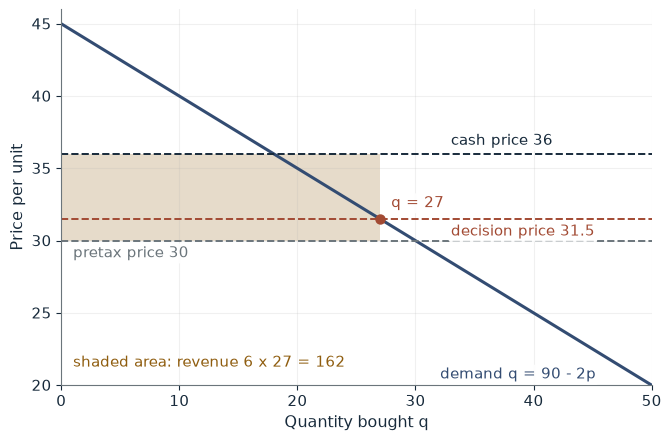

Decision price             31.5
Quantity                   27
Cash price paid            36
Tax revenue                162
Revenue at full attention  108

Worked steps:
  1. Decision price = 30 + 0.25(6) = 31.5
  2. q = 90 - 2(31.5) = 27
  3. Cash price = 30 + 6 = 36
  4. Revenue = 6(27) = 162
  5. Full attention: q = 90 - 2(36) = 18, revenue 6(18) = 108

The decision price is 30 + 0.25 x 6 = 31.5, so q = 90 - 2 x 31.5 = 27. Every unit still costs 36 in cash and raises 6 of tax, so revenue is 162. Buyers notice only 25 percent of the tax, so they buy 9 more units than at full attention (18) and revenue is 162 instead of 108.


In [10]:
show(salience_picture(theta=0.25, t=6))

## Practice

**1.** With a tax of 6 and full attention, what quantity and revenue result?

<details><summary>Answer</summary>

p-tilde = 30 + 6 = 36, q = 90 - 72 = 18 and R = 6(18) = 108.

</details>

**2.** In the long run with a tax of 8, what are p_b, p_s and revenue?

<details><summary>Answer</summary>

180 - 3(p_s + 8) = -45 + 3p_s gives p_s = 33.5, p_b = 41.5, Q = 55.5 and revenue 8(55.5) = 444.

</details>

**3.** With monitoring cost 12 and farm fee 120, which arrangement nets the state more?

<details><summary>Answer</summary>

Monitored administration: 150 - 15 - 12 = 123 > 120.

</details>